In [ ]:
import os
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import spikeinterface as si
import spikeinterface.extractors as se
import spikeinterface.preprocessing as spre
import spikeinterface.postprocessing as spost
import spikeinterface.sorters as ss
import spikeinterface.core as sc
import spikeinterface.widgets as sw
from spikeinterface.sortingcomponents.motion import interpolate_motion
%matplotlib widget


In [2]:
si.__version__


'0.105.2'

In [ ]:
data_path = Path('/Users/jeremy/Desktop/gpr26_161_ephys/20260914/run3/Record Node 101/')

In [ ]:

raw = se.read_openephys(data_path,stream_name="Record Node 101#Neuropix-PXI-112.ProbeA")



In [ ]:
preprocessing_list = [
    {'name':'phase_shift'},
    {'name':'scale_to_physical_units'},
    {'name': 'highpass_filter', 'params': {'freq_min': 500.}},
    {'name': 'gaussian_filter', 'params': {'freq_max': 5000.}},
    {'name':'resample','params': {'resample_rate':15e3}},
    ]

preprocessed_rec1 = spre.apply_preprocessing_pipeline(raw, preprocessing_list)


In [42]:
preprocessed_rec1

ResampleRecording: 384 channels - 15.0kHz - 1 segments - 21,996,082 samples 
                   1,466.41s (24.44 minutes) - float32 dtype - 31.47 GiB

In [4]:
fs = raw.get_sampling_frequency()
raw_sub = raw.frame_slice(start_frame=100*fs, end_frame=120*fs)
raw_sub

FrameSliceRecording: 384 channels - 30.0kHz - 1 segments - 600,000 samples - 20.00s - int16 dtype 
                     439.45 MiB

In [5]:

corrected = spre.phase_shift(raw_sub)

In [6]:
microvolts = spre.scale_to_uV(corrected)

In [7]:
hp_filtered = spre.highpass_filter(microvolts, freq_min=500.0)
lp_filtered = spre.gaussian_filter(hp_filtered, freq_max=5000.0)



In [8]:
dwn_samp = spre.resample(lp_filtered,15e3)
dwn_samp

ResampleRecording: 384 channels - 15.0kHz - 1 segments - 300,000 samples - 20.00s - float32 dtype 
                   439.45 MiB

In [9]:
bad_channels, labels = spre.detect_bad_channels(dwn_samp, method="coherence+psd")

detect_bad_channels (no parallelization):   0%|          | 0/100 [00:00<?, ?it/s]

In [ ]:
all_chan_ids = dwn_samp.get_channel_ids()
out_of_brain = all_chan_ids[all_chan_ids.size-183:] # this is a pretty conservative guess
all_bad_ids = np.concatenate((bad_channels, out_of_brain), axis=0)
all_bad_ids

array(['CH32', 'CH187', 'CH193', 'CH195', 'CH257', 'CH351', 'CH201',
       'CH202', 'CH203', 'CH204', 'CH205', 'CH206', 'CH207', 'CH208',
       'CH209', 'CH210', 'CH211', 'CH212', 'CH213', 'CH214', 'CH215',
       'CH216', 'CH217', 'CH218', 'CH219', 'CH220', 'CH221', 'CH222',
       'CH223', 'CH224', 'CH225', 'CH226', 'CH227', 'CH228', 'CH229',
       'CH230', 'CH231', 'CH232', 'CH233', 'CH234', 'CH235', 'CH236',
       'CH237', 'CH238', 'CH239', 'CH240', 'CH241', 'CH242', 'CH243',
       'CH244', 'CH245', 'CH246', 'CH247', 'CH248', 'CH249', 'CH250',
       'CH251', 'CH252', 'CH253', 'CH254', 'CH255', 'CH256', 'CH257',
       'CH258', 'CH259', 'CH260', 'CH261', 'CH262', 'CH263', 'CH264',
       'CH265', 'CH266', 'CH267', 'CH268', 'CH269', 'CH270', 'CH271',
       'CH272', 'CH273', 'CH274', 'CH275', 'CH276', 'CH277', 'CH278',
       'CH279', 'CH280', 'CH281', 'CH282', 'CH283', 'CH284', 'CH285',
       'CH286', 'CH287', 'CH288', 'CH289', 'CH290', 'CH291', 'CH292',
       'CH293', 'CH29

In [11]:
cleaned = spre.detect_and_remove_bad_channels(recording=dwn_samp, bad_channel_ids=all_bad_ids)

In [12]:
motion_preset = 'dredge'
motion, motion_info = spre.compute_motion(
    cleaned,
    preset=motion_preset,
    output_motion_info=True,
    # Pass the DREDge parameters directly into the motion estimator block
    estimate_motion_kwargs={"batching_mode": "full"} 
)

noise_level (no parallelization):   0%|          | 0/20 [00:00<?, ?it/s]

detect and localize (no parallelization):   0%|          | 0/20 [00:00<?, ?it/s]

Max estimated displacement (um): 0.7760795862142699
Min estimated displacement (um): 0.0010408032708630916


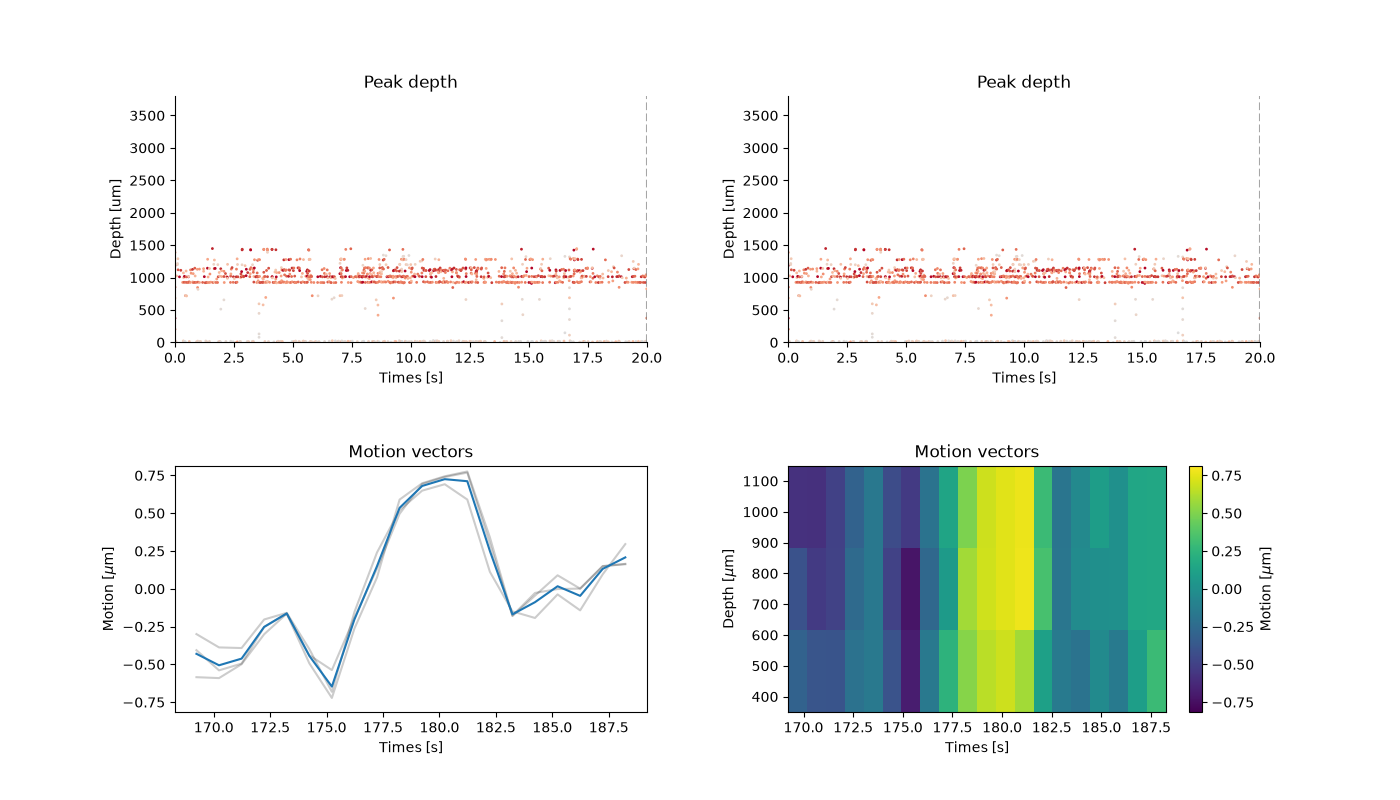

In [13]:
fig = plt.figure(figsize=(14, 8))
sw.plot_motion_info(    
    motion_info, cleaned,
    figure=fig,
    depth_lim=(0, 3800),
    color_amplitude=True,
    amplitude_cmap='coolwarm',
    scatter_decimate=1,
    )
print("Max estimated displacement (um):", np.max(np.abs(motion.displacement)))
print("Min estimated displacement (um):", np.min(np.abs(motion.displacement)))

In [16]:

preset = 'dredge'
interpolated_recording = interpolate_motion(recording=cleaned, motion=motion)
interpolated_recording

interpolate_motion (InterpolateMotionRecording): 194 channels - 15.0kHz - 1 segments 
                    300,000 samples - 20.00s - float32 dtype - 222.02 MiB

(0.0, 1500.0)

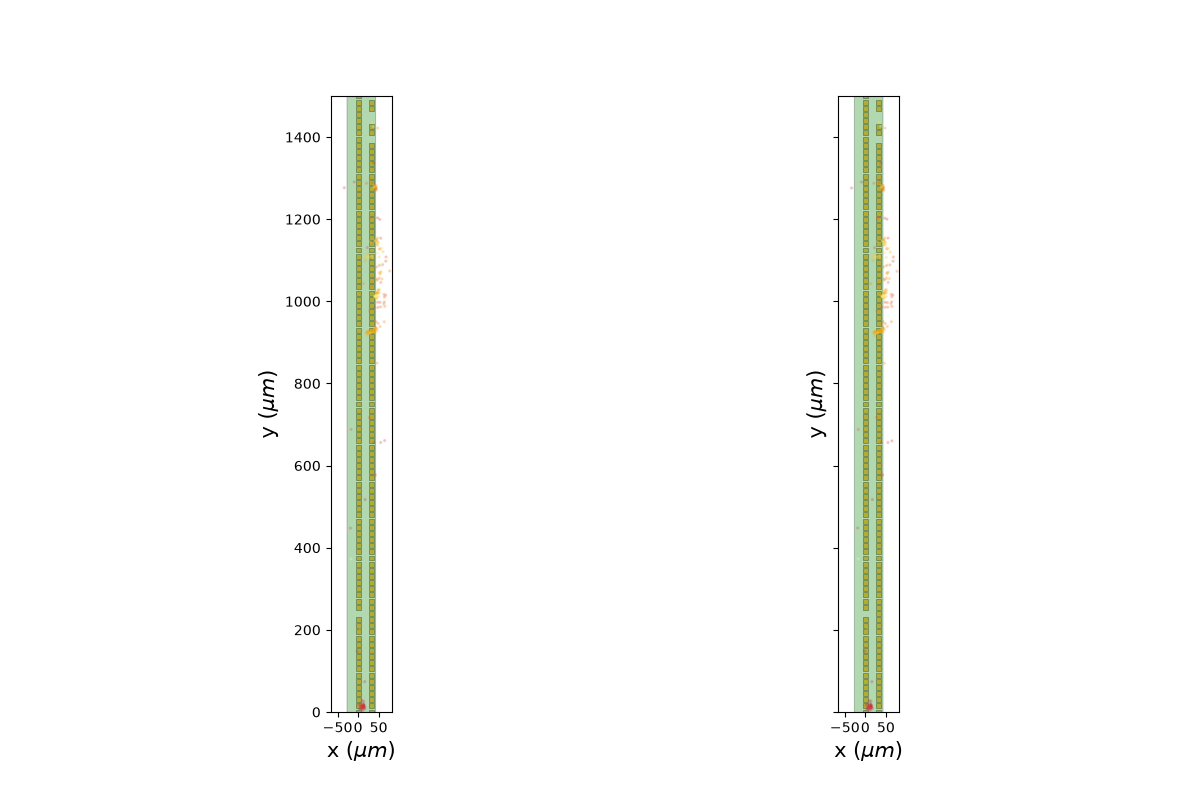

In [14]:
from spikeinterface.sortingcomponents.motion import correct_motion_on_peaks

fig, axs = plt.subplots(ncols=2, figsize=(12, 8), sharey=True)
ax = axs[0]
sw.plot_probe_map(cleaned, ax=ax)
peaks = motion_info["peaks"]
sr = cleaned.get_sampling_frequency()
time_lim0 = 0.0
time_lim1 = 210.0
mask = (peaks["sample_index"] > int(sr * time_lim0)) & (peaks["sample_index"] < int(sr * time_lim1))
sl = slice(None, None, 5)
amps = np.abs(peaks["amplitude"][mask][sl])
amps /= np.quantile(amps, 0.95)
c = plt.get_cmap("inferno")(amps)
color_kargs = dict(alpha=0.2, s=2, c=c)
peak_locations = motion_info["peak_locations"]
ax.scatter(peak_locations["x"][mask][sl], peak_locations["y"][mask][sl], **color_kargs)

peak_locations2 = correct_motion_on_peaks(peaks, peak_locations, motion,cleaned)
ax = axs[1]
sw.plot_probe_map(cleaned, ax=ax)
ax.scatter(peak_locations2["x"][mask][sl], peak_locations2["y"][mask][sl], **color_kargs)

ax.set_ylim(0, 1500)


In [18]:
whitened = spre.whiten(interpolated_recording)
referenced = spre.common_reference(whitened,operator='median', reference='global')


In [19]:
sw.plot_traces(referenced,backend='ipywidgets')

AppLayout(children=(TimeSlider(children=(Dropdown(description='Segment', options=(0,), value=0), Button(icon='…

In [ ]:
job_kwargs = dict(n_jobs=1, chunk_duration="500ms", progress_bar=True)
#corrected.save(folder=output_path / 'preprocessed_binary', format='binary', **job_kwargs)
output_path = Path('/Users/jeremy/Desktop/gpr26_161_ephys/20260914/run2_resting_gnd_ref/')
sorted = ss.run_sorter(
    sorter_name="kilosort4",
    recording=referenced,
    folder= output_path / "kilosort4",
    remove_existing_folder=True,
    use_binary_file=True,
    verbose=True,
    **job_kwargs 
)


write_binary (no parallelization):   0%|          | 0/40 [00:00<?, ?it/s]

kilosort.run_kilosort:  
kilosort.run_kilosort: Computing preprocessing variables.
kilosort.run_kilosort: ----------------------------------------
kilosort.run_kilosort: N samples: 300000
kilosort.run_kilosort: N seconds: 20.0
kilosort.run_kilosort: N batches: 5
kilosort.run_kilosort: Preprocessing filters computed in 0.37s; total 0.37s
kilosort.run_kilosort:  
kilosort.run_kilosort: Resource usage after preprocessing
kilosort.run_kilosort: ********************************************************
kilosort.run_kilosort: CPU usage:    24.30 %
kilosort.run_kilosort: Mem used:     64.10 %     |      10.26 GB
kilosort.run_kilosort: Mem avail:     5.74 / 16.00 GB
kilosort.run_kilosort: ------------------------------------------------------
kilosort.run_kilosort: GPU usage:    N/A
kilosort.run_kilosort: GPU memory:   N/A
kilosort.run_kilosort: ********************************************************
kilosort.run_kilosort:  
kilosort.run_kilosort: Computing drift correction.
kilosort.run_kilos

kilosort4 run time 41.43s


In [22]:
output_path = Path('/Users/jeremy/Desktop/gpr26_161_ephys/20260914/run2_resting_gnd_ref/')
sorted = ss.run_sorter(
    sorter_name="spykingcircus2",
    recording=referenced,
    folder= output_path / "spykingcircus2",
    remove_existing_folder=True,
    verbose=True,
)


Preprocessing the recording (bandpass filtering + CMR + whitening)
Motion correction activated (probe geometry compatible)


noise_level (no parallelization):   0%|          | 0/20 [00:00<?, ?it/s]

detect and localize (no parallelization):   0%|          | 0/20 [00:00<?, ?it/s]

noise_level (no parallelization):   0%|          | 0/20 [00:00<?, ?it/s]

write_memory (no parallelization):   0%|          | 0/20 [00:00<?, ?it/s]

...

find spikes (circus-omp) (no parallelization):   0%|          | 0/20 [00:00<?, ?it/s]

Found 11151 spikes


/Users/jeremy/Documents/python_environments/spikeInterface/lib/python3.12/site-packages/spikeinterface/core/core_tools.py:968: UserWarning: The extractor is not serializable to file. The provenance will not be saved.
  warnings.warn("The extractor is not serializable to file. The provenance will not be saved.")


Kept 126 units after final merging
spykingcircus2 run time 43.89s


/Users/jeremy/Documents/python_environments/spikeInterface/lib/python3.12/site-packages/spikeinterface/core/core_tools.py:968: UserWarning: The extractor is not serializable to file. The provenance will not be saved.
  warnings.warn("The extractor is not serializable to file. The provenance will not be saved.")


In [ ]:
output_path = Path('/Users/jeremy/Desktop/gpr26_161_ephys/20260914/run2_resting_gnd_ref/')
sorted = ss.run_sorter(
    sorter_name="spykingcircus2",
    recording=referenced,
    folder= output_path / "spykingcircus2",
    remove_existing_folder=True,
    verbose=True,
)

In [24]:
output_path = Path('/Users/jeremy/Desktop/gpr26_161_ephys/20260914/run2_resting_gnd_ref/')
sorted = ss.run_sorter(
    sorter_name="tridesclous2",
    recording=referenced,
    folder= output_path / "tridesclous2",
    remove_existing_folder=True,
    verbose=True,
)

write_memory (no parallelization):   0%|          | 0/20 [00:00<?, ?it/s]

noise_level (no parallelization):   0%|          | 0/20 [00:00<?, ?it/s]

detect peaks (locally_exclusive) (no parallelization):   0%|          | 0/20 [00:00<?, ?it/s]

detect_peaks(): 4841 peaks found
select_peaks(): 4841 peaks kept for clustering


Fit peaks svd (no parallelization):   0%|          | 0/20 [00:00<?, ?it/s]

...

estimate_templates_with_accumulator (no parallelization):   0%|          | 0/20 [00:00<?, ?it/s]

/Users/jeremy/Documents/python_environments/spikeInterface/lib/python3.12/site-packages/spikeinterface/core/template_tools.py:397: UserWarning: get_template_peak_shift_on_main_channel() with Templates should provide a peak_sign
  warnings.warn("get_template_peak_shift_on_main_channel() with Templates should provide a peak_sign")


find spikes (tdc-peeler) (no parallelization):   0%|          | 0/20 [00:00<?, ?it/s]

tridesclous2 run time 21.10s


/Users/jeremy/Documents/python_environments/spikeInterface/lib/python3.12/site-packages/spikeinterface/core/core_tools.py:968: UserWarning: The extractor is not serializable to file. The provenance will not be saved.
  warnings.warn("The extractor is not serializable to file. The provenance will not be saved.")


In [25]:
ref_no_white = spre.common_reference(interpolated_recording,operator='median', reference='global')

sort_analyzer = sc.create_sorting_analyzer(sorted,ref_no_white,sparse=True,format='memory')
compute_dict = {
    'random_spikes': {},
    'noise_levels':{},
    'waveforms':{},
    'principal_components': {'n_components': 3, 'mode': 'by_channel_local'},
    'templates': {},
    'template_similarity':{},
    'spike_locations':{},
    'spike_amplitudes':{},
    'correlograms':{},
    'isi_histograms':{}
}

sort_analyzer.compute(compute_dict)
sort_analyzer.compute('quality_metrics')
sort_analyzer.compute('template_metrics')
sort_analyzer.save_as(folder=output_path / 'tridesclous2' / 'sorting_analyzer/',format='binary_folder')




estimate_templates (no parallelization):   0%|          | 0/20 [00:00<?, ?it/s]

noise_level (no parallelization):   0%|          | 0/20 [00:00<?, ?it/s]

compute_waveforms (no parallelization):   0%|          | 0/20 [00:00<?, ?it/s]

Fitting PCA:   0%|          | 0/154 [00:00<?, ?it/s]

Projecting waveforms:   0%|          | 0/154 [00:00<?, ?it/s]

Compute : spike_locations + spike_amplitudes (no parallelization):   0%|          | 0/20 [00:00<?, ?it/s]

/Users/jeremy/Documents/python_environments/spikeInterface/lib/python3.12/site-packages/spikeinterface/metrics/quality/misc_metrics.py:98: UserWarning: Bin duration of 60s is larger than recording duration. Presence ratios are set to NaN.
  warnings.warn(
/Users/jeremy/Documents/python_environments/spikeInterface/lib/python3.12/site-packages/spikeinterface/metrics/quality/misc_metrics.py:1006: UserWarning: Amplitude cutoff set to NaN for units [np.int64(0), np.int64(1), np.int64(4), np.int64(5), np.int64(8), np.int64(13), np.int64(14), np.int64(15), np.int64(17), np.int64(20), np.int64(21), np.int64(24), np.int64(33), np.int64(42), np.int64(43), np.int64(47), np.int64(48), np.int64(51), np.int64(53), np.int64(54), np.int64(56), np.int64(57), np.int64(58), np.int64(59), np.int64(60), np.int64(61), np.int64(62), np.int64(63), np.int64(64), np.int64(65), np.int64(66), np.int64(67), np.int64(68), np.int64(69), np.int64(70), np.int64(71), np.int64(72), np.int64(74), np.int64(76), np.int64(7

SortingAnalyzer: 194 channels - 154 units - 1 segments - binary_folder - sparse - has recording
Loaded 12 extensions: random_spikes, noise_levels, waveforms, principal_components, templates, template_similarity, correlograms, isi_histograms, spike_locations, spike_amplitudes, quality_metrics, template_metrics

In [61]:
referenced

CommonReferenceRecording: 194 channels - 15.0kHz - 1 segments - 300,000 samples - 20.00s 
                          float32 dtype - 222.02 MiB

In [35]:
ss.get_default_sorter_params('tridesclous2')


{'apply_preprocessing': True,
 'preprocessing_dict': None,
 'apply_motion_correction': False,
 'motion_correction_preset': 'dredge_fast',
 'clustering_ms_before': 0.5,
 'clustering_ms_after': 1.5,
 'detection_radius_um': 150.0,
 'features_radius_um': 120.0,
 'split_radius_um': 60.0,
 'template_radius_um': 100.0,
 'merge_similarity_lag_ms': 0.5,
 'freq_min': 150.0,
 'freq_max': 6000.0,
 'cache_preprocessing_mode': 'auto',
 'peak_sign': 'neg',
 'detect_threshold': 5.0,
 'n_peaks_per_channel': 5000,
 'n_svd_components_per_channel': 5,
 'n_pca_features': 6,
 'clustering_recursive_depth': 3,
 'ms_before': 1.0,
 'ms_after': 2.5,
 'template_sparsify_threshold': 1.5,
 'template_min_snr_ptp': 3.5,
 'template_max_jitter_ms': 0.2,
 'min_firing_rate': 0.1,
 'gather_mode': 'memory',
 'job_kwargs': {},
 'seed': None,
 'save_array': True,
 'debug': False}